In [1]:
# ============================================================
# MOD-08 — Ingeniería de Variables
# Proyecto: Impacto Variabilidad Climática en Producción Arrocera
# Versión  : 1.0
# Entrada  : data/master/A2_DF_Imputado.parquet   (MOD-07)
# Salida   : data/master/A3_DF_Features.parquet / .xlsx
#            data/master/A3_Catalogo_Variables.xlsx
# ============================================================
# Variables derivadas construidas:
#   Grupo 1 — Índices de estrés térmico (agronómicos)
#   Grupo 2 — Índices hídricos (balance y riesgo)
#   Grupo 3 — Índices de radiación (eficiencia fotosintética)
#   Grupo 4 — Índices combinados clima-humedad
#   Grupo 5 — Tendencia intra-semestral (regresión lineal m1-m6)
#   Grupo 6 — Codificación de periodo (cíclica y ordinal)
#   Grupo 7 — Interacciones clima × clima
# ============================================================
!pip install openpyxl pyarrow scikit-learn -q

import os, gc, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import stats
warnings.filterwarnings('ignore')

print('✅ Librerías cargadas')


✅ Librerías cargadas


In [2]:
# ============================================================
# CONFIGURACIÓN DE RUTAS — MOD-08
# ============================================================

from google.colab import drive
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')
    print('✅ Google Drive montado')
else:
    print('✅ Google Drive ya montado')

# ── Detección automática ─────────────────────────────────────
RUTA_BASE = None
print()
print('🔍 Buscando carpeta del proyecto...')
for dirpath, dirnames, filenames in os.walk('/content/drive/MyDrive'):
    depth = dirpath.replace('/content/drive/MyDrive', '').count(os.sep)
    if depth > 5:
        dirnames.clear()
        continue
    if 'A2_DF_Imputado.parquet' in filenames:
        candidate = os.path.dirname(os.path.dirname(dirpath))
        if os.path.isdir(os.path.join(candidate, 'data', 'master')):
            RUTA_BASE = candidate
            print(f'   ✅ Proyecto en: {RUTA_BASE}')
            break

if RUTA_BASE is None:
    RUTA_BASE = '/content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II'
    print(f'   ⚠️  Usando ruta manual: {RUTA_BASE}')

RUTA_MASTER = os.path.join(RUTA_BASE, 'data', 'master')
os.makedirs(RUTA_MASTER, exist_ok=True)

# ── Archivos ──────────────────────────────────────────────────
ENTRADA_IMPUTADO    = os.path.join(RUTA_MASTER, 'A2_DF_Imputado.parquet')
SALIDA_FEATURES     = os.path.join(RUTA_MASTER, 'A3_DF_Features.parquet')
SALIDA_FEATURES_XLS = os.path.join(RUTA_MASTER, 'A3_DF_Features.xlsx')
SALIDA_CATALOGO     = os.path.join(RUTA_MASTER, 'A3_Catalogo_Variables.xlsx')

# ── Parámetros agronómicos del arroz ─────────────────────────
# Rangos óptimos para Oryza sativa en Colombia
TEMP_OPTIMA_MIN  = 20.0   # °C — mínimo óptimo para crecimiento
TEMP_OPTIMA_MAX  = 30.0   # °C — máximo óptimo para crecimiento
TEMP_ESTRES_ALTA = 35.0   # °C — umbral estrés térmico alto
TEMP_ESTRES_BAJA = 15.0   # °C — umbral estrés térmico bajo
PREC_OPTIMA_SEM  = 600.0  # mm — precipitación óptima por semestre
PREC_MIN_SEM     = 300.0  # mm — mínimo hídrico por semestre
HR_OPTIMA_MIN    = 60.0   # %  — HR mínima óptima
HR_OPTIMA_MAX    = 80.0   # %  — HR máxima óptima
HR_RIESGO_FUNGICO= 85.0   # %  — umbral riesgo enfermedad fúngica

# ── Verificar entrada ─────────────────────────────────────────
if not os.path.exists(ENTRADA_IMPUTADO):
    raise FileNotFoundError(
        f'No se encontró A2_DF_Imputado.parquet.\n'
        'Ejecuta MOD-07 antes de continuar.'
    )

print()
print('📂 Rutas configuradas:')
print(f'   Master    → {RUTA_MASTER}')
print(f'   Entrada   → A2_DF_Imputado.parquet  ✅')
print()
print('⚙️  Parámetros agronómicos (Oryza sativa):')
print(f'   Temp. óptima        : {TEMP_OPTIMA_MIN}–{TEMP_OPTIMA_MAX} °C')
print(f'   Temp. estrés alto   : > {TEMP_ESTRES_ALTA} °C')
print(f'   Temp. estrés bajo   : < {TEMP_ESTRES_BAJA} °C')
print(f'   Precip. óptima/sem  : {PREC_OPTIMA_SEM} mm')
print(f'   HR óptima           : {HR_OPTIMA_MIN}–{HR_OPTIMA_MAX} %')
print(f'   HR riesgo fúngico   : > {HR_RIESGO_FUNGICO} %')


Mounted at /content/drive
✅ Google Drive montado

🔍 Buscando carpeta del proyecto...
   ✅ Proyecto en: /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II

📂 Rutas configuradas:
   Master    → /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/master
   Entrada   → A2_DF_Imputado.parquet  ✅

⚙️  Parámetros agronómicos (Oryza sativa):
   Temp. óptima        : 20.0–30.0 °C
   Temp. estrés alto   : > 35.0 °C
   Temp. estrés bajo   : < 15.0 °C
   Precip. óptima/sem  : 600.0 mm
   HR óptima           : 60.0–80.0 %
   HR riesgo fúngico   : > 85.0 %


In [3]:
# ============================================================
# FUNCIONES UTILITARIAS — MOD-08
# ============================================================
import re as _re

def detectar_bases(df, prefijo):
    """Detecta métricas base: temperatura_media, temperatura_maxima, etc."""
    patron = _re.compile(
        rf'^({_re.escape(prefijo)}[^_]+(?:_[^_]+)*)_m([1-6])$'
    )
    bases = set()
    for col in df.columns:
        m = patron.match(col)
        if m:
            bases.add(m.group(1))
    return sorted(bases)


def cols_m(df, base, n_meses=6):
    """Retorna las columnas mN disponibles para una base."""
    return [f'{base}_m{n}' for n in range(1, n_meses+1)
            if f'{base}_m{n}' in df.columns]


def safe_row_mean(df, col_list):
    """Media por fila ignorando NaN; NaN si todas son NaN."""
    present = [c for c in col_list if c in df.columns]
    return df[present].mean(axis=1) if present else pd.Series(np.nan, index=df.index)


def safe_row_sum(df, col_list):
    """Suma por fila ignorando NaN."""
    present = [c for c in col_list if c in df.columns]
    return df[present].sum(axis=1, min_count=1) if present else pd.Series(np.nan, index=df.index)


def safe_row_max(df, col_list):
    present = [c for c in col_list if c in df.columns]
    return df[present].max(axis=1) if present else pd.Series(np.nan, index=df.index)


def safe_row_min(df, col_list):
    present = [c for c in col_list if c in df.columns]
    return df[present].min(axis=1) if present else pd.Series(np.nan, index=df.index)


def pendiente_lineal(df, col_list):
    """
    Calcula la pendiente de la regresión lineal Y ~ X
    donde X = [1,2,...,N] (índice del mes) e Y = valores de las columnas.
    Retorna Serie con la pendiente por fila (tendencia intra-semestral).
    Un valor positivo indica incremento a lo largo del semestre;
    negativo indica decremento.
    """
    present = [c for c in col_list if c in df.columns]
    if len(present) < 2:
        return pd.Series(np.nan, index=df.index)
    X = np.arange(1, len(present) + 1, dtype=float)
    mat = df[present].values.astype(float)
    # Regresión OLS vectorizada: pendiente = Cov(X,Y) / Var(X)
    X_c = X - X.mean()
    var_X = np.dot(X_c, X_c)
    mat_c = mat - np.nanmean(mat, axis=1, keepdims=True)
    pendientes = np.nansum(mat_c * X_c, axis=1) / var_X
    return pd.Series(pendientes, index=df.index)


def registrar_variable(catalogo, nombre, grupo, formula, interpretacion, unidad=''):
    """Añade una variable al catálogo de trazabilidad."""
    catalogo.append({
        'variable'      : nombre,
        'grupo'         : grupo,
        'formula'       : formula,
        'interpretacion': interpretacion,
        'unidad'        : unidad,
    })


print('✅ Funciones utilitarias cargadas')


✅ Funciones utilitarias cargadas


In [4]:
# ============================================================
# CARGAR A2_DF_Imputado E INVENTARIAR COLUMNAS
# ============================================================

print('📥 Cargando A2_DF_Imputado.parquet...')
df = pd.read_parquet(ENTRADA_IMPUTADO)

for col in ['Periodo', 'Departamento', 'Municipio']:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip().str.upper()

print(f'   Shape : {df.shape[0]:,} filas × {df.shape[1]} cols')
print(f'   Periodos: {sorted(df["Periodo"].unique())}')
print()

# ── Inventariar columnas por tipo ────────────────────────────
COLS_ID     = [c for c in df.columns
               if c in ['Periodo','Departamento','Municipio',
                        'Año','Semestre','Cuadrante',
                        'Cultivo','Desagregación cultivo','Es_Top500']]
COLS_TARGET = [c for c in df.columns
               if any(k in c for k in ['Producción','Rendimiento',
                                        'Área','Produccion','Area'])]

# Columnas climáticas base (sin _var)
COLS_TEMP_BASE = sorted([c for c in df.columns
                          if c.startswith('temperatura_') and not c.endswith('_var')])
COLS_PREC_BASE = sorted([c for c in df.columns
                          if c.startswith('precipitacion_') and not c.endswith('_var')])
COLS_RAD_BASE  = sorted([c for c in df.columns
                          if c.startswith('radiacion_') and not c.endswith('_var')])
COLS_HR_BASE   = sorted([c for c in df.columns
                          if c.startswith('hr_') and not c.endswith('_var')])
COLS_VAR_BASE  = sorted([c for c in df.columns if c.endswith('_var')])

# Bases detectadas por bloque
BASES_TEMP = detectar_bases(df, 'temperatura_')
BASES_PREC = detectar_bases(df, 'precipitacion_')
BASES_RAD  = detectar_bases(df, 'radiacion_')
BASES_HR   = detectar_bases(df, 'hr_')

# Inicializar catálogo
CATALOGO = []

print('📋 Inventario de columnas en A2:')
print(f'   ID + meta       : {len(COLS_ID)}   {COLS_ID}')
print(f'   Target          : {len(COLS_TARGET)}   {COLS_TARGET}')
print(f'   Temp. base      : {len(COLS_TEMP_BASE)}  bases={BASES_TEMP}')
print(f'   Prec. base      : {len(COLS_PREC_BASE)}  bases={BASES_PREC}')
print(f'   Rad.  base      : {len(COLS_RAD_BASE)}  bases={BASES_RAD}')
print(f'   HR    base      : {len(COLS_HR_BASE)}  bases={BASES_HR}')
print(f'   Varianzas (MOD07): {len(COLS_VAR_BASE)}')
print()
print('   Todos los nulos climáticos: ',
      df[COLS_TEMP_BASE+COLS_PREC_BASE+COLS_RAD_BASE+COLS_HR_BASE].isna().sum().sum())

# Inicializar df_feat con copia base (no modifica df original)
df_feat = df.copy()


📥 Cargando A2_DF_Imputado.parquet...
   Shape : 173 filas × 143 cols
   Periodos: ['2020A', '2020B', '2021A', '2021B', '2022A', '2022B', '2023A', '2023B', '2024A', '2024B']

📋 Inventario de columnas en A2:
   ID + meta       : 7   ['Periodo', 'Departamento', 'Municipio', 'Año', 'Cuadrante', 'Cultivo', 'Desagregación cultivo']
   Target          : 4   ['Área sembrada (ha)', 'Área cosechada (ha)', 'Producción (t)', 'Rendimiento (t/ha)']
   Temp. base      : 24  bases=['temperatura_maxima', 'temperatura_media', 'temperatura_minima', 'temperatura_std']
   Prec. base      : 30  bases=['precipitacion_maxima', 'precipitacion_media', 'precipitacion_minima', 'precipitacion_std', 'precipitacion_total']
   Rad.  base      : 12  bases=['radiacion_allsky', 'radiacion_clearsky']
   HR    base      : 36  bases=['hr_dias_riesgo_alto', 'hr_dias_riesgo_bajo', 'hr_maxima', 'hr_media', 'hr_minima', 'hr_std']
   Varianzas (MOD07): 17

   Todos los nulos climáticos:  0


In [5]:
# ============================================================
# GRUPO 1 — ÍNDICES DE ESTRÉS TÉRMICO
#
# CONSTRUCCIÓN Y JUSTIFICACIÓN AGRONÓMICA:
# ─────────────────────────────────────────
# El arroz (Oryza sativa) tiene requerimientos térmicos precisos.
# La temperatura media óptima para su desarrollo es 20-30 °C.
# Temperaturas > 35 °C durante la antesis reducen la fertilidad
# del polen hasta un 80% (IRRI, 2015). Temperaturas < 15 °C
# retardan la germinación y el macollamiento.
#
# Variables construidas:
#
# temp_media_sem    : Promedio simple de temperatura_media_m1..m6
#   → Resumen térmico del semestre. Captura la temperatura
#     característica del ciclo de cultivo completo.
#
# temp_amplitud_sem : max(temperatura_maxima_mN) - min(temperatura_minima_mN)
#   → Amplitud térmica semestral. Alta amplitud indica mayor
#     estrés diario; el arroz prefiere amplitudes < 15 °C.
#
# temp_dias_estres_alto : conteo de meses con temp_maxima > 35 °C
#   → Proxy de meses con riesgo de esterilidad del grano.
#     Cada mes en zona de estrés reduce potencial de rendimiento.
#
# temp_dias_estres_bajo : conteo de meses con temp_minima < 15 °C
#   → Proxy de meses con riesgo de retardo en crecimiento.
#
# temp_fuera_optimo_pct : fracción de meses con temp_media fuera [20,30] °C
#   → Proporción del semestre en condiciones subóptimas.
#     0 = semestre ideal; 1 = semestre totalmente fuera del óptimo.
#
# temp_grados_optimos   : suma de (temp_media - TEMP_OPTIMA_MIN) para meses en [20,30]
#   → "Temperatura acumulada útil". Relacionada con la tasa de
#     desarrollo fisiológico dentro del rango óptimo.
# ============================================================

print('='*62)
print('  GRUPO 1 — ÍNDICES DE ESTRÉS TÉRMICO')
print('='*62)
print()

G = 'G1_Estres_Termico'
n_antes = df_feat.shape[1]

col_t_media  = 'temperatura_media'
col_t_max    = 'temperatura_maxima'
col_t_min    = 'temperatura_minima'

cm_media = cols_m(df_feat, col_t_media)
cm_max   = cols_m(df_feat, col_t_max)
cm_min   = cols_m(df_feat, col_t_min)

# ── 1.1 Temperatura media semestral ──────────────────────────
if cm_media:
    df_feat['temp_media_sem'] = safe_row_mean(df_feat, cm_media)
    registrar_variable(CATALOGO, 'temp_media_sem', G,
        f'mean({", ".join(cm_media)})',
        'Temperatura media del semestre. Indicador térmico global del ciclo.', '°C')

# ── 1.2 Amplitud térmica semestral ───────────────────────────
if cm_max and cm_min:
    df_feat['temp_amplitud_sem'] = (
        safe_row_max(df_feat, cm_max) - safe_row_min(df_feat, cm_min)
    )
    registrar_variable(CATALOGO, 'temp_amplitud_sem', G,
        f'max({col_t_max}_mN) - min({col_t_min}_mN)',
        'Amplitud térmica semestral. Alta amplitud = mayor estrés diario.', '°C')

# ── 1.3 Meses con estrés térmico alto ────────────────────────
if cm_max:
    df_feat['temp_meses_estres_alto'] = (
        df_feat[cm_max].gt(TEMP_ESTRES_ALTA).sum(axis=1)
    )
    registrar_variable(CATALOGO, 'temp_meses_estres_alto', G,
        f'count({col_t_max}_mN > {TEMP_ESTRES_ALTA})',
        f'Meses con temp. máx. > {TEMP_ESTRES_ALTA}°C. Riesgo esterilidad polen.', 'meses')

# ── 1.4 Meses con estrés térmico bajo ────────────────────────
if cm_min:
    df_feat['temp_meses_estres_bajo'] = (
        df_feat[cm_min].lt(TEMP_ESTRES_BAJA).sum(axis=1)
    )
    registrar_variable(CATALOGO, 'temp_meses_estres_bajo', G,
        f'count({col_t_min}_mN < {TEMP_ESTRES_BAJA})',
        f'Meses con temp. mín. < {TEMP_ESTRES_BAJA}°C. Riesgo retardo crecimiento.', 'meses')

# ── 1.5 Fracción fuera del óptimo térmico ────────────────────
if cm_media:
    n_meses = len(cm_media)
    fuera = (
        df_feat[cm_media].lt(TEMP_OPTIMA_MIN) |
        df_feat[cm_media].gt(TEMP_OPTIMA_MAX)
    ).sum(axis=1)
    df_feat['temp_fuera_optimo_pct'] = fuera / n_meses
    registrar_variable(CATALOGO, 'temp_fuera_optimo_pct', G,
        f'count({col_t_media}_mN < {TEMP_OPTIMA_MIN} OR > {TEMP_OPTIMA_MAX}) / {n_meses}',
        f'Fracción de meses fuera de [{TEMP_OPTIMA_MIN},{TEMP_OPTIMA_MAX}]°C. 0=ideal, 1=totalmente fuera.', 'ratio')

# ── 1.6 Temperatura acumulada en rango óptimo ────────────────
if cm_media:
    mask_optimo = (
        (df_feat[cm_media] >= TEMP_OPTIMA_MIN) &
        (df_feat[cm_media] <= TEMP_OPTIMA_MAX)
    )
    temp_util = df_feat[cm_media].where(mask_optimo, other=np.nan)
    df_feat['temp_grados_optimos'] = (
        (temp_util - TEMP_OPTIMA_MIN).clip(lower=0).sum(axis=1, min_count=1)
    )
    registrar_variable(CATALOGO, 'temp_grados_optimos', G,
        f'sum(max(0, {col_t_media}_mN - {TEMP_OPTIMA_MIN})) para meses en óptimo',
        'Acumulado térmico útil en rango óptimo. Mayor valor = mejor condición térmica.', '°C·meses')

n_nuevas = df_feat.shape[1] - n_antes
print(f'   Variables creadas: {n_nuevas}')
nuevas = [c for c in df_feat.columns if c not in df.columns][:n_nuevas]
for v in nuevas:
    media = df_feat[v].mean()
    print(f'   ✅ {v:<40}  media={media:.4f}')


  GRUPO 1 — ÍNDICES DE ESTRÉS TÉRMICO

   Variables creadas: 6
   ✅ temp_media_sem                            media=25.0485
   ✅ temp_amplitud_sem                         media=19.7561
   ✅ temp_meses_estres_alto                    media=2.5954
   ✅ temp_meses_estres_bajo                    media=1.0867
   ✅ temp_fuera_optimo_pct                     media=0.1580
   ✅ temp_grados_optimos                       media=31.0613


In [6]:
# ============================================================
# GRUPO 2 — ÍNDICES HÍDRICOS
#
# CONSTRUCCIÓN Y JUSTIFICACIÓN AGRONÓMICA:
# ─────────────────────────────────────────
# El arroz es el cultivo de mayor demanda hídrica: requiere
# 1000–2000 mm/ciclo según el sistema (irrigado vs secano).
# La distribución temporal de la lluvia importa tanto como
# el volumen total (CIAT, 2018).
#
# prec_total_sem    : suma de precipitacion_total_m1..m6
#   → Precipitación acumulada del semestre. Referencia directa
#     para evaluar déficit o exceso hídrico global.
#
# prec_media_mensual: media de precipitacion_total_mN
#   → Lluvia mensual promedio. Útil para comparar regímenes
#     pluviales entre departamentos y periodos.
#
# prec_deficit_sem  : max(0, PREC_OPTIMA_SEM - prec_total_sem)
#   → Déficit hídrico absoluto respecto al óptimo (600 mm).
#     Cero indica condición óptima o superávit.
#
# prec_exceso_sem   : max(0, prec_total_sem - PREC_OPTIMA_SEM)
#   → Exceso hídrico. Encharcamiento > 800 mm/sem reduce
#     oxigenación radicular y favorece enfermedades.
#
# prec_coef_variacion: cv = std(prec_mN) / mean(prec_mN)
#   → Irregularidad de la lluvia intra-semestral.
#     CV > 0.5 indica distribución muy irregular (riesgo).
#
# prec_meses_secos  : conteo de meses con prec_total < 50 mm
#   → Meses de sequía relativa durante el ciclo.
#     El arroz en floración es sensible incluso a sequías cortas.
#
# prec_concentracion: max(prec_total_mN) / prec_total_sem
#   → Fracción del total caído en el mes más lluvioso.
#     Alta concentración = riesgo de inundación puntual.
# ============================================================

print('='*62)
print('  GRUPO 2 — ÍNDICES HÍDRICOS')
print('='*62)
print()

G = 'G2_Hidrico'
n_antes = df_feat.shape[1]

col_p_total = 'precipitacion_total'
cm_ptotal   = cols_m(df_feat, col_p_total)
col_p_media = 'precipitacion_media'
cm_pmedia   = cols_m(df_feat, col_p_media)
col_p_std   = 'precipitacion_std'
cm_pstd     = cols_m(df_feat, col_p_std)

# ── 2.1 Precipitación total semestral ────────────────────────
if cm_ptotal:
    df_feat['prec_total_sem'] = safe_row_sum(df_feat, cm_ptotal)
    registrar_variable(CATALOGO, 'prec_total_sem', G,
        f'sum({", ".join(cm_ptotal)})',
        'Precipitación acumulada del semestre. Referencia de disponibilidad hídrica.', 'mm')

# ── 2.2 Precipitación media mensual ──────────────────────────
if cm_ptotal:
    df_feat['prec_media_mensual'] = safe_row_mean(df_feat, cm_ptotal)
    registrar_variable(CATALOGO, 'prec_media_mensual', G,
        f'mean({col_p_total}_mN)',
        'Lluvia mensual promedio en el semestre.', 'mm/mes')

# ── 2.3 Déficit hídrico ───────────────────────────────────────
if 'prec_total_sem' in df_feat.columns:
    df_feat['prec_deficit_sem'] = (
        (PREC_OPTIMA_SEM - df_feat['prec_total_sem']).clip(lower=0)
    )
    registrar_variable(CATALOGO, 'prec_deficit_sem', G,
        f'max(0, {PREC_OPTIMA_SEM} - prec_total_sem)',
        f'Déficit hídrico respecto al óptimo ({PREC_OPTIMA_SEM} mm). 0=sin déficit.', 'mm')

# ── 2.4 Exceso hídrico ───────────────────────────────────────
if 'prec_total_sem' in df_feat.columns:
    df_feat['prec_exceso_sem'] = (
        (df_feat['prec_total_sem'] - PREC_OPTIMA_SEM).clip(lower=0)
    )
    registrar_variable(CATALOGO, 'prec_exceso_sem', G,
        f'max(0, prec_total_sem - {PREC_OPTIMA_SEM})',
        f'Exceso hídrico sobre el óptimo ({PREC_OPTIMA_SEM} mm). Riesgo encharcamiento.', 'mm')

# ── 2.5 Coeficiente de variación de la lluvia ────────────────
if cm_ptotal and len(cm_ptotal) >= 2:
    mat = df_feat[cm_ptotal]
    std_p  = mat.std(axis=1, ddof=1)
    mean_p = mat.mean(axis=1)
    df_feat['prec_coef_variacion'] = std_p / mean_p.replace(0, np.nan)
    registrar_variable(CATALOGO, 'prec_coef_variacion', G,
        f'std({col_p_total}_mN) / mean({col_p_total}_mN)',
        'Irregularidad intra-semestral. CV > 0.5 = distribución muy irregular (riesgo).', 'ratio')

# ── 2.6 Meses secos (prec < 50 mm) ───────────────────────────
if cm_ptotal:
    df_feat['prec_meses_secos'] = (
        df_feat[cm_ptotal].lt(50).sum(axis=1)
    )
    registrar_variable(CATALOGO, 'prec_meses_secos', G,
        f'count({col_p_total}_mN < 50)',
        'Meses con precipitación < 50 mm. Proxy de sequía durante el ciclo.', 'meses')

# ── 2.7 Concentración mensual de la lluvia ────────────────────
if cm_ptotal and 'prec_total_sem' in df_feat.columns:
    df_feat['prec_concentracion'] = (
        safe_row_max(df_feat, cm_ptotal) /
        df_feat['prec_total_sem'].replace(0, np.nan)
    )
    registrar_variable(CATALOGO, 'prec_concentracion', G,
        f'max({col_p_total}_mN) / prec_total_sem',
        'Fracción del total en el mes más lluvioso. Alta = riesgo inundación puntual.', 'ratio')

n_nuevas = df_feat.shape[1] - n_antes
print(f'   Variables creadas: {n_nuevas}')
cols_nuevas_g2 = [c for c in df_feat.columns
                  if c not in df.columns and c not in
                  [r['variable'] for r in CATALOGO if r['grupo'] != 'G2_Hidrico']]
for v in [r['variable'] for r in CATALOGO if r['grupo'] == 'G2_Hidrico']:
    if v in df_feat.columns:
        media = df_feat[v].mean()
        print(f'   ✅ {v:<40}  media={media:.4f}')


  GRUPO 2 — ÍNDICES HÍDRICOS

   Variables creadas: 7
   ✅ prec_total_sem                            media=1008.5536
   ✅ prec_media_mensual                        media=168.0923
   ✅ prec_deficit_sem                          media=129.2207
   ✅ prec_exceso_sem                           media=537.7744
   ✅ prec_coef_variacion                       media=0.9672
   ✅ prec_meses_secos                          media=2.4393
   ✅ prec_concentracion                        media=0.4224


In [7]:
# ============================================================
# GRUPO 3 — ÍNDICES DE RADIACIÓN SOLAR
#
# CONSTRUCCIÓN Y JUSTIFICACIÓN AGRONÓMICA:
# ─────────────────────────────────────────
# La radiación solar es el motor de la fotosíntesis. En arroz,
# la radiación durante el periodo reproductivo (floración a
# llenado de grano) es el factor ambiental más correlacionado
# con el rendimiento (Yoshida, 1981; IRRI).
#
# rad_allsky_sem      : media de radiacion_allsky_mN
#   → Radiación promedio real (con nubes) del semestre.
#     Es la energía disponible efectiva para la planta.
#
# rad_clearsky_sem    : media de radiacion_clearsky_mN
#   → Radiación potencial (cielo despejado). Referencia
#     del máximo disponible en la ubicación geográfica.
#
# rad_fraccion_solar  : rad_allsky_sem / rad_clearsky_sem
#   → Índice de transmisividad atmosférica (0-1).
#     Fracción de la radiación potencial que llega a la superficie.
#     Bajo = alta nubosidad = menor fotosíntesis potencial.
#     Es un proxy de la disponibilidad de luz durante el ciclo.
#
# rad_deficit_nubosidad: rad_clearsky_sem - rad_allsky_sem
#   → Pérdida de radiación por nubosidad (MJ/m²/día).
#     Alta nubosidad reduce el índice de área foliar activo
#     y puede retrasar la maduración del grano.
#
# rad_max_mensual     : max de radiacion_allsky_mN
#   → Mes de máxima radiación. Indica cuándo hubo mayor
#     disponibilidad de luz (potencial de crecimiento máximo).
# ============================================================

print('='*62)
print('  GRUPO 3 — ÍNDICES DE RADIACIÓN SOLAR')
print('='*62)
print()

G = 'G3_Radiacion'
n_antes = df_feat.shape[1]

col_allsky   = 'radiacion_allsky'
col_clearsky = 'radiacion_clearsky'
cm_allsky    = cols_m(df_feat, col_allsky)
cm_clearsky  = cols_m(df_feat, col_clearsky)

# ── 3.1 Radiación media semestral (real) ─────────────────────
if cm_allsky:
    df_feat['rad_allsky_sem'] = safe_row_mean(df_feat, cm_allsky)
    registrar_variable(CATALOGO, 'rad_allsky_sem', G,
        f'mean({", ".join(cm_allsky)})',
        'Radiación solar media real del semestre (con nubosidad).', 'MJ/m²/día')

# ── 3.2 Radiación media semestral (cielo despejado) ──────────
if cm_clearsky:
    df_feat['rad_clearsky_sem'] = safe_row_mean(df_feat, cm_clearsky)
    registrar_variable(CATALOGO, 'rad_clearsky_sem', G,
        f'mean({", ".join(cm_clearsky)})',
        'Radiación potencial media del semestre (sin nubosidad). Referencia máxima.', 'MJ/m²/día')

# ── 3.3 Fracción solar (transmisividad) ──────────────────────
if 'rad_allsky_sem' in df_feat.columns and 'rad_clearsky_sem' in df_feat.columns:
    df_feat['rad_fraccion_solar'] = (
        df_feat['rad_allsky_sem'] /
        df_feat['rad_clearsky_sem'].replace(0, np.nan)
    ).clip(0, 1)
    registrar_variable(CATALOGO, 'rad_fraccion_solar', G,
        'rad_allsky_sem / rad_clearsky_sem',
        'Transmisividad (0-1). Bajo = alta nubosidad. Proxy de luz disponible para fotosíntesis.', 'ratio')

# ── 3.4 Déficit por nubosidad ─────────────────────────────────
if 'rad_allsky_sem' in df_feat.columns and 'rad_clearsky_sem' in df_feat.columns:
    df_feat['rad_deficit_nubosidad'] = (
        df_feat['rad_clearsky_sem'] - df_feat['rad_allsky_sem']
    ).clip(lower=0)
    registrar_variable(CATALOGO, 'rad_deficit_nubosidad', G,
        'rad_clearsky_sem - rad_allsky_sem',
        'Pérdida de radiación por nubosidad. Mayor = mayor cobertura nubosa.', 'MJ/m²/día')

# ── 3.5 Radiación máxima mensual ─────────────────────────────
if cm_allsky:
    df_feat['rad_max_mensual'] = safe_row_max(df_feat, cm_allsky)
    registrar_variable(CATALOGO, 'rad_max_mensual', G,
        f'max({col_allsky}_mN)',
        'Máxima radiación en el mes más soleado del semestre.', 'MJ/m²/día')

n_nuevas = df_feat.shape[1] - n_antes
print(f'   Variables creadas: {n_nuevas}')
for r in CATALOGO:
    if r['grupo'] == 'G3_Radiacion' and r['variable'] in df_feat.columns:
        media = df_feat[r['variable']].mean()
        print(f'   ✅ {r["variable"]:<40}  media={media:.4f}')


  GRUPO 3 — ÍNDICES DE RADIACIÓN SOLAR

   Variables creadas: 5
   ✅ rad_allsky_sem                            media=17.1271
   ✅ rad_clearsky_sem                          media=24.9006
   ✅ rad_fraccion_solar                        media=0.6890
   ✅ rad_deficit_nubosidad                     media=7.7735
   ✅ rad_max_mensual                           media=18.9729


In [8]:
# ============================================================
# GRUPO 4 — ÍNDICES COMBINADOS CLIMA-HUMEDAD
#
# CONSTRUCCIÓN Y JUSTIFICACIÓN AGRONÓMICA:
# ─────────────────────────────────────────
# Las variables climáticas no actúan de forma independiente.
# La combinación temperatura+humedad determina condiciones
# fitosanitarias, mientras que temperatura+precipitación
# define el balance hídrico-térmico del cultivo.
#
# hr_media_sem        : media de hr_media_mN
#   → Humedad relativa media del semestre.
#
# hr_meses_riesgo_fungico : conteo de meses con hr_maxima > 85 %
#   → Meses con condiciones propicias para enfermedades fúngicas
#     (Pyricularia oryzae, Rhizoctonia solani). Critical para arroz.
#
# hr_meses_estres_bajo : conteo de meses con hr_media < 60 %
#   → Baja HR indica estrés hídrico atmosférico que aumenta la
#     transpiración y puede causar cierre estomático.
#
# indice_calor_humedo : temp_media_sem × (hr_media_sem / 100)
#   → Combina temperatura y humedad en un solo índice.
#     Alta temperatura + alta humedad = condiciones de calor
#     húmedo que estresan a la planta y favorecen patógenos.
#
# indice_aridez_sem   : prec_total_sem / (temp_media_sem + 10)
#   → Adaptación del Índice de Martonne (simplificado).
#     < 5 = árido; 5-15 = semi-árido; > 15 = húmedo.
#     Caracteriza el régimen climático del semestre.
#
# balance_hidrotermico: prec_total_sem / temp_media_sem
#   → Relación lluvia/temperatura. Captura si la disponibilidad
#     hídrica es coherente con la demanda evapotranspirativa.
# ============================================================

print('='*62)
print('  GRUPO 4 — ÍNDICES COMBINADOS CLIMA-HUMEDAD')
print('='*62)
print()

G = 'G4_Combinado'
n_antes = df_feat.shape[1]

cm_hr_media = cols_m(df_feat, 'hr_media')
cm_hr_max   = cols_m(df_feat, 'hr_maxima')

# ── 4.1 HR media semestral ────────────────────────────────────
if cm_hr_media:
    df_feat['hr_media_sem'] = safe_row_mean(df_feat, cm_hr_media)
    registrar_variable(CATALOGO, 'hr_media_sem', G,
        f'mean({", ".join(cm_hr_media)})',
        'Humedad relativa media del semestre.', '%')

# ── 4.2 Meses con riesgo fúngico ─────────────────────────────
if cm_hr_max:
    df_feat['hr_meses_riesgo_fungico'] = (
        df_feat[cm_hr_max].gt(HR_RIESGO_FUNGICO).sum(axis=1)
    )
    registrar_variable(CATALOGO, 'hr_meses_riesgo_fungico', G,
        f'count(hr_maxima_mN > {HR_RIESGO_FUNGICO})',
        f'Meses con HR máx. > {HR_RIESGO_FUNGICO}%. Riesgo Pyricularia y Rhizoctonia.', 'meses')

# ── 4.3 Meses con estrés por baja HR ─────────────────────────
if cm_hr_media:
    df_feat['hr_meses_estres_bajo'] = (
        df_feat[cm_hr_media].lt(HR_OPTIMA_MIN).sum(axis=1)
    )
    registrar_variable(CATALOGO, 'hr_meses_estres_bajo', G,
        f'count(hr_media_mN < {HR_OPTIMA_MIN})',
        f'Meses con HR media < {HR_OPTIMA_MIN}%. Estrés hídrico atmosférico.', 'meses')

# ── 4.4 Índice de calor húmedo ────────────────────────────────
if 'temp_media_sem' in df_feat.columns and 'hr_media_sem' in df_feat.columns:
    df_feat['indice_calor_humedo'] = (
        df_feat['temp_media_sem'] * (df_feat['hr_media_sem'] / 100)
    )
    registrar_variable(CATALOGO, 'indice_calor_humedo', G,
        'temp_media_sem × (hr_media_sem / 100)',
        'Calor-humedad combinado. Alto = estrés higrotérmico y riesgo fitosanitario.', '°C')

# ── 4.5 Índice de aridez semestral (Martonne simplificado) ────
if 'prec_total_sem' in df_feat.columns and 'temp_media_sem' in df_feat.columns:
    df_feat['indice_aridez_sem'] = (
        df_feat['prec_total_sem'] /
        (df_feat['temp_media_sem'] + 10).replace(0, np.nan)
    )
    registrar_variable(CATALOGO, 'indice_aridez_sem', G,
        'prec_total_sem / (temp_media_sem + 10)',
        'Índice de Martonne simplificado. <5=árido, 5-15=semi-árido, >15=húmedo.', 'mm/°C')

# ── 4.6 Balance hidrotérmico ──────────────────────────────────
if 'prec_total_sem' in df_feat.columns and 'temp_media_sem' in df_feat.columns:
    df_feat['balance_hidrotermico'] = (
        df_feat['prec_total_sem'] /
        df_feat['temp_media_sem'].replace(0, np.nan)
    )
    registrar_variable(CATALOGO, 'balance_hidrotermico', G,
        'prec_total_sem / temp_media_sem',
        'Relación lluvia/temperatura. Coherencia entre oferta hídrica y demanda evapotranspirativa.', 'mm/°C')

n_nuevas = df_feat.shape[1] - n_antes
print(f'   Variables creadas: {n_nuevas}')
for r in CATALOGO:
    if r['grupo'] == 'G4_Combinado' and r['variable'] in df_feat.columns:
        media = df_feat[r['variable']].mean()
        print(f'   ✅ {r["variable"]:<40}  media={media:.4f}')


  GRUPO 4 — ÍNDICES COMBINADOS CLIMA-HUMEDAD

   Variables creadas: 6
   ✅ hr_media_sem                              media=76.3742
   ✅ hr_meses_riesgo_fungico                   media=5.6185
   ✅ hr_meses_estres_bajo                      media=0.4277
   ✅ indice_calor_humedo                       media=19.0632
   ✅ indice_aridez_sem                         media=29.9066
   ✅ balance_hidrotermico                      media=42.8160


In [9]:
# ============================================================
# GRUPO 5 — TENDENCIAS INTRA-SEMESTRALES (REGRESIÓN LINEAL)
#
# CONSTRUCCIÓN Y JUSTIFICACIÓN AGRONÓMICA:
# ─────────────────────────────────────────
# La dirección del cambio climático dentro del semestre puede
# ser tan importante como el nivel medio. Un semestre que empieza
# frío y termina cálido (tendencia positiva) tiene implicaciones
# diferentes para el cultivo que uno uniformemente cálido.
#
# Método:
#   Se ajusta una regresión lineal Y ~ X donde:
#   X = [1, 2, 3, 4, 5, 6]  (índice del mes dentro del semestre)
#   Y = valores de la variable en m1..m6
#   Pendiente β₁ = cambio promedio por mes durante el semestre
#
# temp_media_tendencia    : pendiente de temperatura_media_m1..m6
#   → β₁ > 0: semestre que se calienta progresivamente.
#     Esto puede coincidir con la fase reproductiva tardía
#     y afectar el llenado de grano.
#   → β₁ < 0: semestre que se enfría (favorece macollamiento).
#
# prec_total_tendencia    : pendiente de precipitacion_total_m1..m6
#   → β₁ > 0: lluvias crecientes (semestre con más lluvia al final).
#     Puede indicar inicio de temporada lluviosa dentro del semestre.
#   → β₁ < 0: lluvias decrecientes (sequía progresiva).
#
# hr_media_tendencia      : pendiente de hr_media_m1..m6
#   → Cambio de humedad a lo largo del semestre.
#     Tendencias positivas + temp. alta = riesgo fúngico creciente.
#
# rad_allsky_tendencia    : pendiente de radiacion_allsky_m1..m6
#   → β₁ > 0: más luz al avanzar el semestre (positivo para
#     llenado de grano si coincide con fase reproductiva).
# ============================================================

print('='*62)
print('  GRUPO 5 — TENDENCIAS INTRA-SEMESTRALES')
print('='*62)
print()

G = 'G5_Tendencia'
n_antes = df_feat.shape[1]

tendencias = [
    ('temperatura_media',    'temp_media_tendencia',
     'Tendencia térmica. β>0=semestre se calienta, β<0=se enfría.', '°C/mes'),
    ('precipitacion_total',  'prec_total_tendencia',
     'Tendencia pluviométrica. β>0=lluvias crecientes, β<0=decrecientes.', 'mm/mes'),
    ('hr_media',             'hr_media_tendencia',
     'Tendencia de HR. β>0=humedad creciente (riesgo fúngico tardío).', '%/mes'),
    ('radiacion_allsky',     'rad_allsky_tendencia',
     'Tendencia de radiación. β>0=más sol al avanzar el semestre.', 'MJ/m²/día/mes'),
]

for base, nombre_var, interp, unidad in tendencias:
    cm_base = cols_m(df_feat, base)
    if len(cm_base) >= 2:
        df_feat[nombre_var] = pendiente_lineal(df_feat, cm_base)
        registrar_variable(CATALOGO, nombre_var, G,
            f'pendiente lineal de {base}_m1..m{len(cm_base)} ~ [1..{len(cm_base)}]',
            interp, unidad)

n_nuevas = df_feat.shape[1] - n_antes
print(f'   Variables creadas: {n_nuevas}')
for r in CATALOGO:
    if r['grupo'] == 'G5_Tendencia' and r['variable'] in df_feat.columns:
        media = df_feat[r['variable']].mean()
        pct_pos = (df_feat[r['variable']] > 0).mean() * 100
        print(f'   ✅ {r["variable"]:<40}  media={media:+.4f}  ({pct_pos:.0f}% positivos)')


  GRUPO 5 — TENDENCIAS INTRA-SEMESTRALES

   Variables creadas: 4
   ✅ temp_media_tendencia                      media=-0.1259  (29% positivos)
   ✅ prec_total_tendencia                      media=+18.7698  (67% positivos)
   ✅ hr_media_tendencia                        media=+1.6019  (79% positivos)
   ✅ rad_allsky_tendencia                      media=-0.2682  (29% positivos)


In [10]:
# ============================================================
# GRUPO 6 — CODIFICACIÓN DEL PERIODO
#
# CONSTRUCCIÓN Y JUSTIFICACIÓN:
# ──────────────────────────────
# Los modelos de ML no interpretan directamente strings
# como '2020A'. Se necesitan representaciones numéricas
# que preserven las propiedades cíclicas y ordinales del tiempo.
#
# periodo_anio     : año extraído de Periodo (ej. 2020)
#   → Variable ordinal. Captura tendencias de largo plazo
#     (cambio climático, cambios en tecnología agrícola).
#
# periodo_semestre_num : 0=semestre A (ene-jun), 1=semestre B (jul-dic)
#   → Variable binaria. Captura la estacionalidad principal.
#     El semestre A suele ser más lluvioso en Colombia (ENSO).
#
# periodo_ordinal  : índice secuencial del periodo (0,1,2,...)
#   → Tiempo continuo. Permite capturar tendencias lineales
#     en modelos que no manejan fechas directamente.
#
# periodo_sin / periodo_cos : codificación cíclica del semestre
#   → Representación sin/cos para que el modelo "entienda"
#     que después del semestre B viene el A del año siguiente
#     sin discontinuidad. Evita el error de tratar la
#     ciclicidad como una variable lineal.
#     periodo_sin = sin(2π × semestre_num / 2)
#     periodo_cos = cos(2π × semestre_num / 2)
# ============================================================

print('='*62)
print('  GRUPO 6 — CODIFICACIÓN DEL PERIODO')
print('='*62)
print()

G = 'G6_Periodo'
n_antes = df_feat.shape[1]

# Extraer año y semestre desde Periodo (ej. '2020A', '2021B')
if 'Periodo' in df_feat.columns:
    per = df_feat['Periodo'].astype(str).str.strip().str.upper()

    # Año
    df_feat['periodo_anio'] = pd.to_numeric(
        per.str.extract(r'(\d{4})')[0], errors='coerce'
    ).astype('Int64')
    registrar_variable(CATALOGO, 'periodo_anio', G,
        'int(Periodo[:4])',
        'Año del periodo. Captura tendencias de largo plazo.', 'año')

    # Semestre numérico
    df_feat['periodo_semestre_num'] = per.str.extract(r'([AB])$')[0].map(
        {'A': 0, 'B': 1}
    ).astype('Int64')
    registrar_variable(CATALOGO, 'periodo_semestre_num', G,
        "0 si Periodo termina en 'A', 1 si termina en 'B'",
        'Semestre numérico (0=A, 1=B). Captura estacionalidad principal.', 'binario')

    # Índice ordinal del periodo
    periodos_ord = sorted(df_feat['Periodo'].unique())
    mapa_ord = {p: i for i, p in enumerate(periodos_ord)}
    df_feat['periodo_ordinal'] = df_feat['Periodo'].map(mapa_ord).astype('Int64')
    registrar_variable(CATALOGO, 'periodo_ordinal', G,
        'rank ordinal de Periodo en orden cronológico',
        'Tiempo continuo. Captura tendencias lineales sobre la serie temporal.', 'entero')

    # Codificación cíclica
    sem_num = df_feat['periodo_semestre_num'].fillna(0).astype(float)
    df_feat['periodo_sin'] = np.sin(2 * np.pi * sem_num / 2)
    df_feat['periodo_cos'] = np.cos(2 * np.pi * sem_num / 2)
    registrar_variable(CATALOGO, 'periodo_sin', G,
        'sin(2π × periodo_semestre_num / 2)',
        'Codificación cíclica: proyección seno. Preserva continuidad A→B→A.', '')
    registrar_variable(CATALOGO, 'periodo_cos', G,
        'cos(2π × periodo_semestre_num / 2)',
        'Codificación cíclica: proyección coseno. Par con periodo_sin.', '')

n_nuevas = df_feat.shape[1] - n_antes
print(f'   Variables creadas: {n_nuevas}')
print()
print('   Distribución de periodos:')
for per_val in sorted(df_feat['Periodo'].unique()):
    ord_val = mapa_ord.get(per_val, '?')
    sem_val = per_val[-1] if per_val else '?'
    sem_num_val = 0 if sem_val == 'A' else 1
    print(f'   {per_val}  → ordinal={ord_val}  semestre_num={sem_num_val}  '
          f'sin={np.sin(2*np.pi*sem_num_val/2):.3f}  '
          f'cos={np.cos(2*np.pi*sem_num_val/2):.3f}')


  GRUPO 6 — CODIFICACIÓN DEL PERIODO

   Variables creadas: 5

   Distribución de periodos:
   2020A  → ordinal=0  semestre_num=0  sin=0.000  cos=1.000
   2020B  → ordinal=1  semestre_num=1  sin=0.000  cos=-1.000
   2021A  → ordinal=2  semestre_num=0  sin=0.000  cos=1.000
   2021B  → ordinal=3  semestre_num=1  sin=0.000  cos=-1.000
   2022A  → ordinal=4  semestre_num=0  sin=0.000  cos=1.000
   2022B  → ordinal=5  semestre_num=1  sin=0.000  cos=-1.000
   2023A  → ordinal=6  semestre_num=0  sin=0.000  cos=1.000
   2023B  → ordinal=7  semestre_num=1  sin=0.000  cos=-1.000
   2024A  → ordinal=8  semestre_num=0  sin=0.000  cos=1.000
   2024B  → ordinal=9  semestre_num=1  sin=0.000  cos=-1.000


In [11]:
# ============================================================
# GRUPO 7 — INTERACCIONES CLIMA × CLIMA
#
# CONSTRUCCIÓN Y JUSTIFICACIÓN:
# ──────────────────────────────
# Los modelos lineales no capturan interacciones entre variables.
# Estas variables de interacción exponen relaciones no lineales
# que son biológicamente relevantes para el cultivo del arroz.
#
# interact_temp_x_prec   : temp_media_sem × prec_total_sem
#   → Interacción temperatura-lluvia. Captura que el efecto
#     de la temperatura sobre el rendimiento depende del agua
#     disponible (alta T + poca lluvia = estrés severo).
#
# interact_temp_x_hr     : temp_media_sem × hr_media_sem
#   → Similar al índice de calor húmedo pero sin normalizar.
#     Útil para modelos de árbol que gestionan escalas distintas.
#
# interact_rad_x_prec    : rad_allsky_sem × prec_total_sem
#   → Energía × agua. Proxy del potencial productivo bruto:
#     luz suficiente + agua disponible = alta biomasa potencial.
#
# interact_deficit_x_temp: prec_deficit_sem × temp_media_sem
#   → Interacción estrés hídrico × temperatura.
#     Un déficit hídrico a alta temperatura es mucho más dañino
#     (mayor evapotranspiración potencial no satisfecha).
#
# interact_hr_x_temp_estres: hr_meses_riesgo_fungico × temp_meses_estres_alto
#   → Co-ocurrencia de condiciones fúngicas y térmicas extremas.
#     Ambas condiciones simultáneas multiplican el riesgo fitosanitario.
# ============================================================

print('='*62)
print('  GRUPO 7 — INTERACCIONES CLIMA × CLIMA')
print('='*62)
print()

G = 'G7_Interacciones'
n_antes = df_feat.shape[1]

def safe_interact(df, col_a, col_b, nombre):
    """Producto de dos columnas, ambas deben existir."""
    if col_a in df.columns and col_b in df.columns:
        df[nombre] = df[col_a] * df[col_b]
        return True
    return False

# ── 7.1 Temp × Precipitación ──────────────────────────────────
if safe_interact(df_feat, 'temp_media_sem', 'prec_total_sem', 'interact_temp_x_prec'):
    registrar_variable(CATALOGO, 'interact_temp_x_prec', G,
        'temp_media_sem × prec_total_sem',
        'Interacción temperatura-lluvia. Alta T + poca lluvia = estrés severo combinado.', '°C·mm')

# ── 7.2 Temp × HR ─────────────────────────────────────────────
if safe_interact(df_feat, 'temp_media_sem', 'hr_media_sem', 'interact_temp_x_hr'):
    registrar_variable(CATALOGO, 'interact_temp_x_hr', G,
        'temp_media_sem × hr_media_sem',
        'Temperatura × humedad sin normalizar. Captura estrés higrotérmico bruto.', '°C·%')

# ── 7.3 Radiación × Precipitación ────────────────────────────
if safe_interact(df_feat, 'rad_allsky_sem', 'prec_total_sem', 'interact_rad_x_prec'):
    registrar_variable(CATALOGO, 'interact_rad_x_prec', G,
        'rad_allsky_sem × prec_total_sem',
        'Luz × agua. Proxy de potencial productivo bruto del semestre.', 'MJ·mm/m²')

# ── 7.4 Déficit hídrico × Temperatura ────────────────────────
if safe_interact(df_feat, 'prec_deficit_sem', 'temp_media_sem', 'interact_deficit_x_temp'):
    registrar_variable(CATALOGO, 'interact_deficit_x_temp', G,
        'prec_deficit_sem × temp_media_sem',
        'Déficit hídrico amplificado por temperatura. Mayor T = mayor daño por déficit.', 'mm·°C')

# ── 7.5 Riesgo fúngico × Estrés térmico alto ─────────────────
if safe_interact(df_feat,
                 'hr_meses_riesgo_fungico', 'temp_meses_estres_alto',
                 'interact_hr_x_temp_estres'):
    registrar_variable(CATALOGO, 'interact_hr_x_temp_estres', G,
        'hr_meses_riesgo_fungico × temp_meses_estres_alto',
        'Co-ocurrencia condiciones fúngicas + estrés térmico. Riesgo fitosanitario máximo.', 'meses²')

n_nuevas = df_feat.shape[1] - n_antes
print(f'   Variables creadas: {n_nuevas}')
for r in CATALOGO:
    if r['grupo'] == 'G7_Interacciones' and r['variable'] in df_feat.columns:
        media = df_feat[r['variable']].mean()
        print(f'   ✅ {r["variable"]:<44}  media={media:.4f}')


  GRUPO 7 — INTERACCIONES CLIMA × CLIMA

   Variables creadas: 5
   ✅ interact_temp_x_prec                          media=24297.3809
   ✅ interact_temp_x_hr                            media=1906.3248
   ✅ interact_rad_x_prec                           media=16876.6621
   ✅ interact_deficit_x_temp                       media=3409.2500
   ✅ interact_hr_x_temp_estres                     media=15.0289


In [12]:
# ============================================================
# REORGANIZAR COLUMNAS, OPTIMIZAR TIPOS Y CONTROL DE CALIDAD
# ============================================================

sep = '='*65
print(sep)
print('  INVENTARIO FINAL — A3_DF_Features')
print(sep)
print()

# Columnas nuevas creadas en MOD-08
COLS_NUEVAS = [r['variable'] for r in CATALOGO if r['variable'] in df_feat.columns]

# Ordenar: ID → Target → Features base → Variables nuevas por grupo
GRUPOS_ORDEN = ['G1_Estres_Termico','G2_Hidrico','G3_Radiacion',
                'G4_Combinado','G5_Tendencia','G6_Periodo','G7_Interacciones']

orden = COLS_ID.copy()
orden += COLS_TARGET
orden += COLS_TEMP_BASE + COLS_PREC_BASE + COLS_RAD_BASE + COLS_HR_BASE
orden += COLS_VAR_BASE

for grp in GRUPOS_ORDEN:
    orden += [r['variable'] for r in CATALOGO
              if r['grupo'] == grp and r['variable'] in df_feat.columns]

orden_final = [c for c in orden if c in df_feat.columns]
cols_extra  = [c for c in df_feat.columns if c not in orden_final]
df_features = df_feat[orden_final + cols_extra].copy()

# Optimizar tipos float
cols_float_nuevas = [c for c in COLS_NUEVAS if df_features[c].dtype in ['float64','float32']]
for col in cols_float_nuevas:
    df_features[col] = df_features[col].astype('float32')

# ── Control de calidad ────────────────────────────────────────
print('QC — Variables derivadas:')
print(f'   {"Variable":<44}  {"Media":>10}  {"Nulos":>6}  {"Min":>8}  {"Max":>8}')
print(f'   {"-"*86}')
for grp in GRUPOS_ORDEN:
    vars_grp = [r['variable'] for r in CATALOGO
                if r['grupo'] == grp and r['variable'] in df_features.columns]
    if vars_grp:
        print(f'\n   ── {grp} ──')
        for v in vars_grp:
            s     = df_features[v].dropna()
            n_nan = df_features[v].isna().sum()
            if len(s) > 0:
                print(f'   {v:<44}  {s.mean():>10.3f}  {n_nan:>6}  '
                      f'{s.min():>8.3f}  {s.max():>8.3f}')

print()
print(f'  Shape final  : {df_features.shape[0]:,} filas × {df_features.shape[1]} cols')
print(f'  Cols A2 base : {df.shape[1]}')
print(f'  Vars nuevas  : {len(COLS_NUEVAS)}')
print(f'  Total nulos  : {df_features.isna().sum().sum():,}')

print()
print('  Resumen por grupo:')
for grp in GRUPOS_ORDEN:
    n = sum(1 for r in CATALOGO if r['grupo'] == grp and r['variable'] in df_features.columns)
    print(f'   {grp:<30}: {n:>2} variables')
print(f'   {"TOTAL":<30}: {len(COLS_NUEVAS):>2} variables derivadas')


  INVENTARIO FINAL — A3_DF_Features

QC — Variables derivadas:
   Variable                                           Media   Nulos       Min       Max
   --------------------------------------------------------------------------------------

   ── G1_Estres_Termico ──
   temp_media_sem                                    25.048       0    14.411    32.073
   temp_amplitud_sem                                 19.756       0    13.800    39.000
   temp_meses_estres_alto                             2.595       0     0.000     6.000
   temp_meses_estres_bajo                             1.087       0     0.000     6.000
   temp_fuera_optimo_pct                              0.158       0     0.000     1.000
   temp_grados_optimos                               31.061       9     0.094    53.501

   ── G2_Hidrico ──
   prec_total_sem                                  1008.554       0     0.000  14767.580
   prec_media_mensual                               168.092       0     0.000  2461.263
   pr

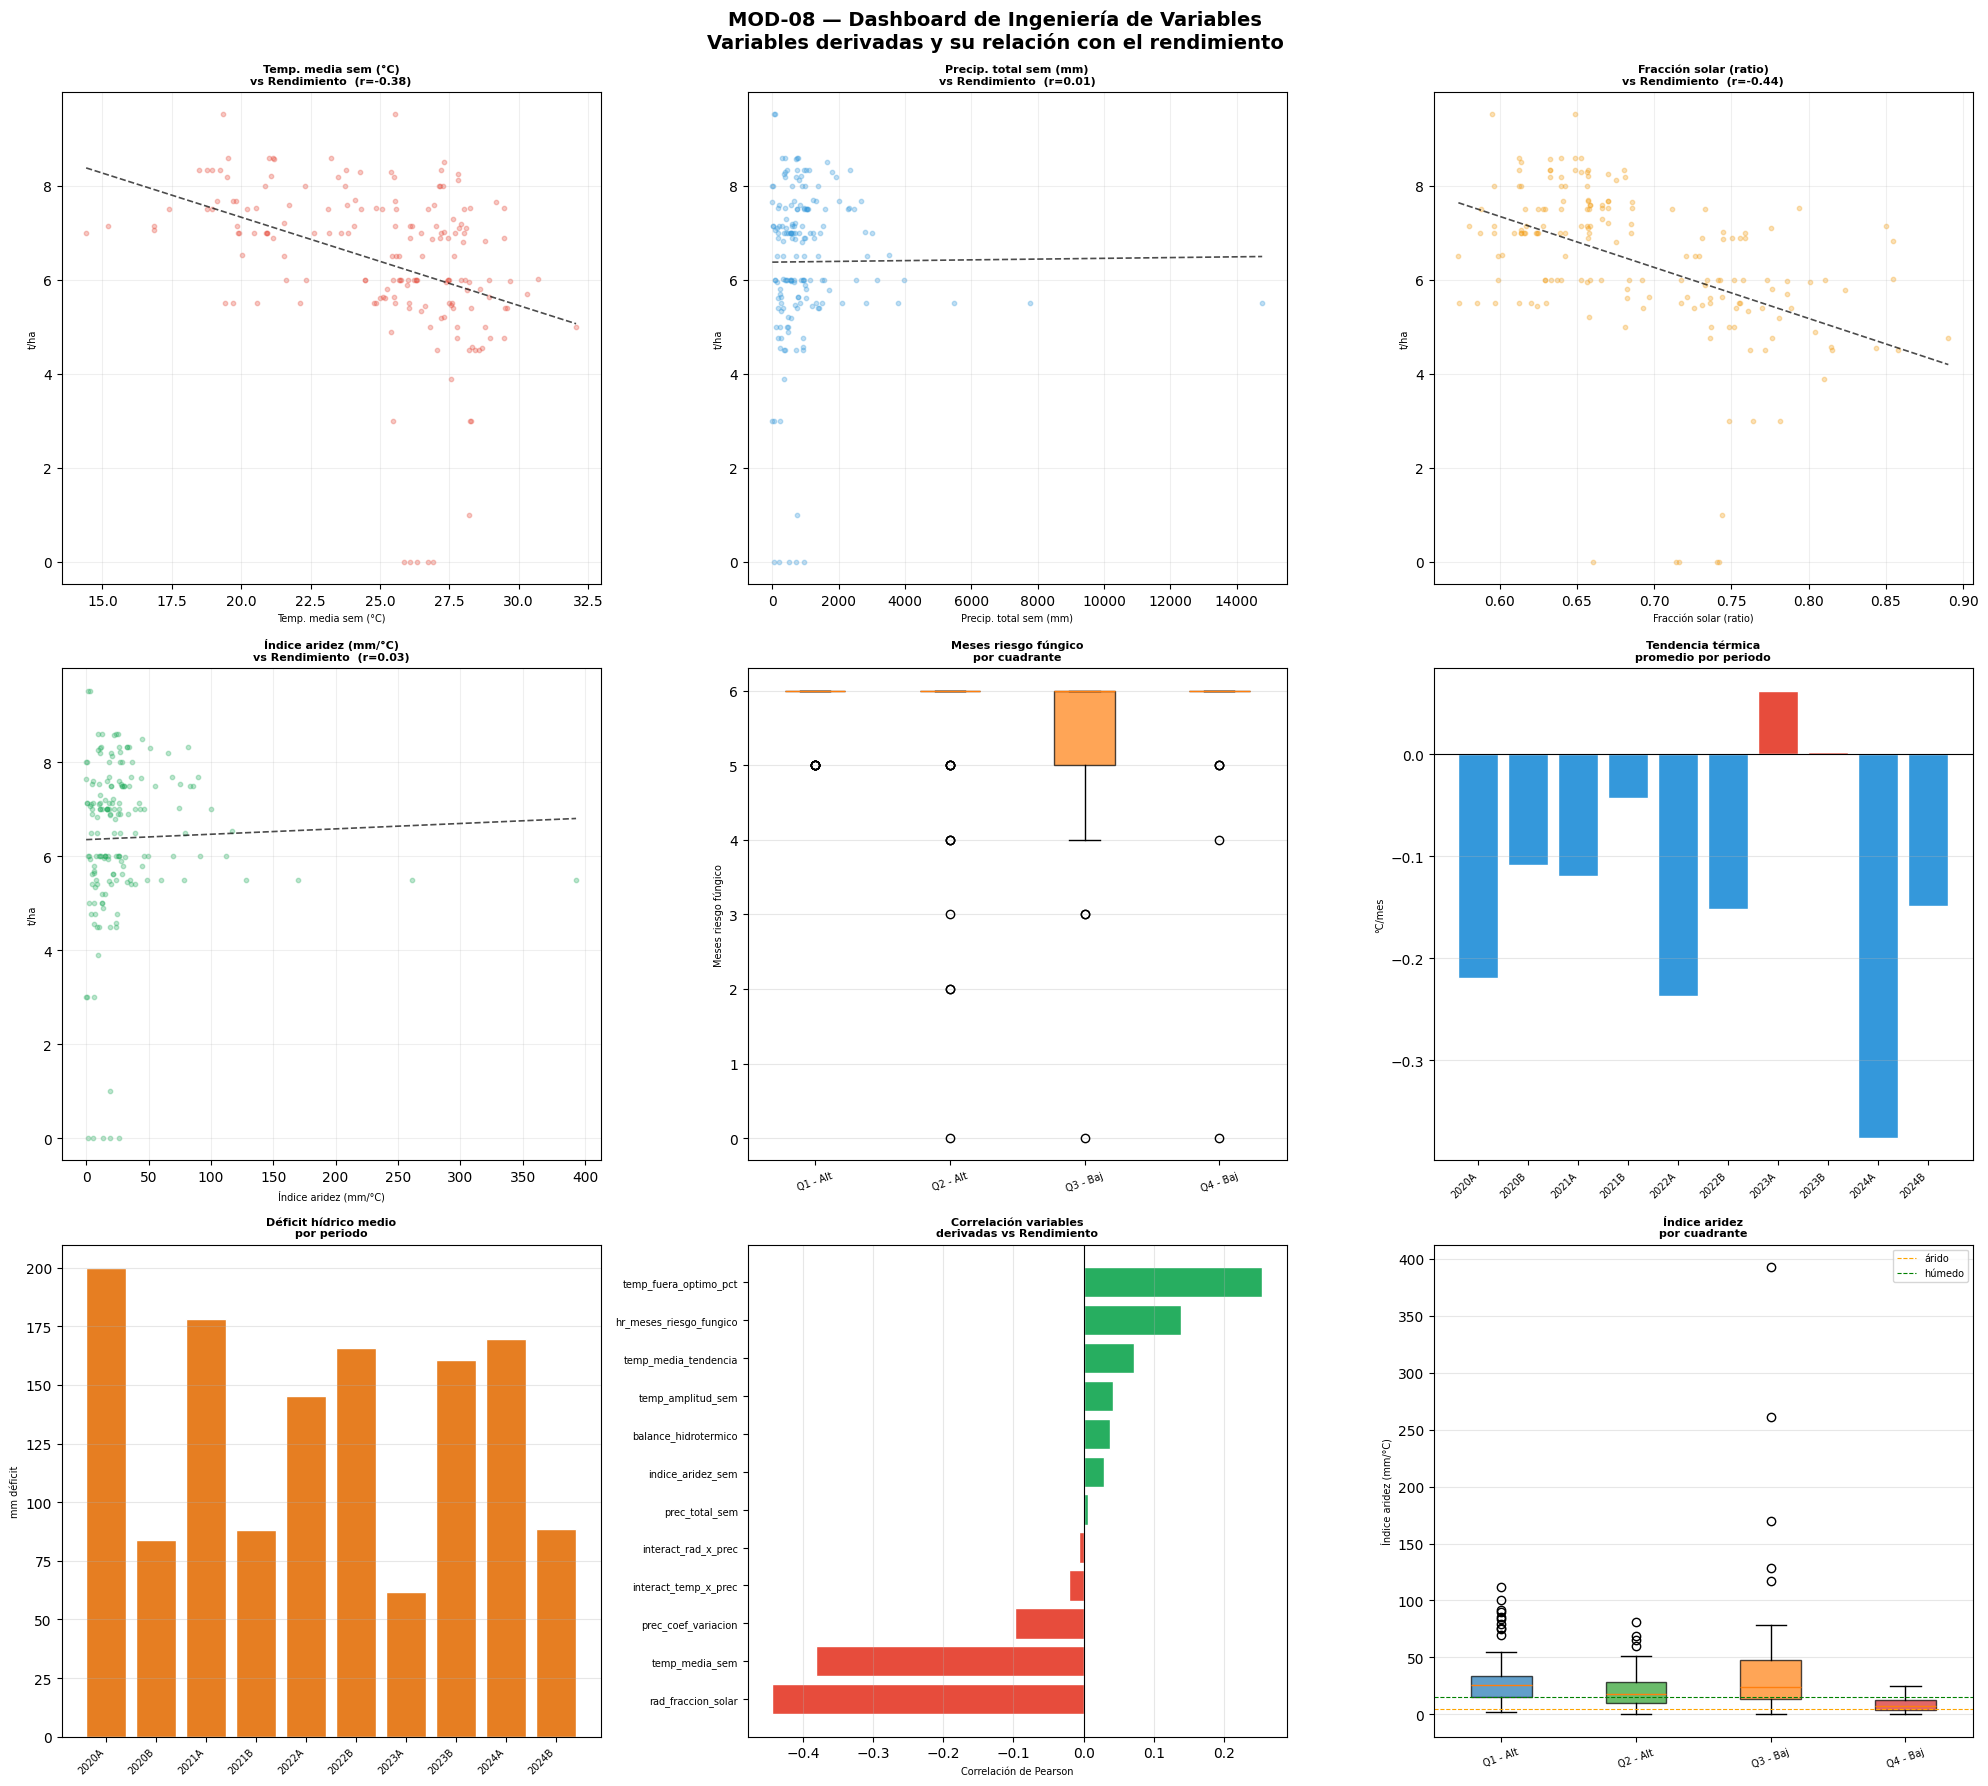

✅ Dashboard guardado: A3_Dashboard_Features.png


In [13]:
# ============================================================
# DASHBOARD — Variables derivadas de ingeniería
# ============================================================

fig = plt.figure(figsize=(20, 18))
fig.suptitle(
    'MOD-08 — Dashboard de Ingeniería de Variables\n'
    'Variables derivadas y su relación con el rendimiento',
    fontsize=14, fontweight='bold', y=0.99
)

col_rend = next((c for c in COLS_TARGET if 'Rendimiento' in c or 'rendimiento' in c), None)

def scatter_vs_rend(ax, col_x, label_x, color):
    if col_x in df_features.columns and col_rend:
        sc = df_features[[col_x, col_rend]].dropna()
        ax.scatter(sc[col_x], sc[col_rend], alpha=0.3, s=10, c=color)
        if len(sc) > 2:
            m, b, r, p, _ = stats.linregress(sc[col_x], sc[col_rend])
            xr = np.linspace(sc[col_x].min(), sc[col_x].max(), 50)
            ax.plot(xr, m*xr+b, 'k--', lw=1.2, alpha=0.7)
            ax.set_title(f'{label_x}\nvs Rendimiento  (r={r:.2f})',
                         fontsize=8, fontweight='bold')
        else:
            ax.set_title(f'{label_x}\nvs Rendimiento', fontsize=8, fontweight='bold')
        ax.set_xlabel(label_x, fontsize=7)
        ax.set_ylabel('t/ha', fontsize=7)
        ax.grid(alpha=0.2)

# Panel 1: Temp media sem vs rendimiento
ax1 = fig.add_subplot(3, 3, 1)
scatter_vs_rend(ax1, 'temp_media_sem', 'Temp. media sem (°C)', '#e74c3c')

# Panel 2: Prec total sem vs rendimiento
ax2 = fig.add_subplot(3, 3, 2)
scatter_vs_rend(ax2, 'prec_total_sem', 'Precip. total sem (mm)', '#3498db')

# Panel 3: Fracción solar vs rendimiento
ax3 = fig.add_subplot(3, 3, 3)
scatter_vs_rend(ax3, 'rad_fraccion_solar', 'Fracción solar (ratio)', '#f39c12')

# Panel 4: Índice aridez vs rendimiento
ax4 = fig.add_subplot(3, 3, 4)
scatter_vs_rend(ax4, 'indice_aridez_sem', 'Índice aridez (mm/°C)', '#27ae60')

# Panel 5: HR riesgo fúngico (boxplot por cuadrante)
ax5 = fig.add_subplot(3, 3, 5)
if 'hr_meses_riesgo_fungico' in df_features.columns and 'Cuadrante' in df_features.columns:
    cuads = sorted(df_features['Cuadrante'].dropna().unique())
    data_q = [df_features[df_features['Cuadrante']==q]['hr_meses_riesgo_fungico'].dropna().values
              for q in cuads]
    colores_q = ['#1f77b4','#2ca02c','#ff7f0e','#d62728']
    bp = ax5.boxplot(data_q, patch_artist=True)
    for patch, color in zip(bp['boxes'], colores_q[:len(cuads)]):
        patch.set_facecolor(color); patch.set_alpha(0.7)
    ax5.set_xticklabels([q[:8] for q in cuads], fontsize=7, rotation=20)
    ax5.set_ylabel('Meses riesgo fúngico', fontsize=7)
    ax5.set_title('Meses riesgo fúngico\npor cuadrante', fontsize=8, fontweight='bold')
    ax5.grid(axis='y', alpha=0.3)

# Panel 6: Tendencia de temperatura por periodo
ax6 = fig.add_subplot(3, 3, 6)
if 'temp_media_tendencia' in df_features.columns and 'Periodo' in df_features.columns:
    tend_per = df_features.groupby('Periodo')['temp_media_tendencia'].mean().sort_index()
    colors_tend = ['#e74c3c' if v > 0 else '#3498db' for v in tend_per.values]
    ax6.bar(range(len(tend_per)), tend_per.values, color=colors_tend, edgecolor='white')
    ax6.axhline(0, color='black', lw=0.8)
    ax6.set_xticks(range(len(tend_per)))
    ax6.set_xticklabels(tend_per.index, rotation=45, ha='right', fontsize=7)
    ax6.set_ylabel('°C/mes', fontsize=7)
    ax6.set_title('Tendencia térmica\npromedio por periodo', fontsize=8, fontweight='bold')
    ax6.grid(axis='y', alpha=0.3)

# Panel 7: Déficit hídrico por semestre
ax7 = fig.add_subplot(3, 3, 7)
if 'prec_deficit_sem' in df_features.columns and 'Periodo' in df_features.columns:
    def_per = df_features.groupby('Periodo')['prec_deficit_sem'].mean().sort_index()
    ax7.bar(range(len(def_per)), def_per.values, color='#e67e22', edgecolor='white')
    ax7.set_xticks(range(len(def_per)))
    ax7.set_xticklabels(def_per.index, rotation=45, ha='right', fontsize=7)
    ax7.set_ylabel('mm déficit', fontsize=7)
    ax7.set_title('Déficit hídrico medio\npor periodo', fontsize=8, fontweight='bold')
    ax7.grid(axis='y', alpha=0.3)

# Panel 8: Correlaciones de variables derivadas con rendimiento
ax8 = fig.add_subplot(3, 3, 8)
if col_rend:
    vars_corr_candidates = [
        'temp_media_sem','prec_total_sem','rad_fraccion_solar',
        'indice_aridez_sem','temp_fuera_optimo_pct','hr_meses_riesgo_fungico',
        'balance_hidrotermico','temp_media_tendencia','prec_coef_variacion',
        'interact_temp_x_prec','interact_rad_x_prec','temp_amplitud_sem',
    ]
    vars_corr = [v for v in vars_corr_candidates if v in df_features.columns]
    corrs = df_features[vars_corr + [col_rend]].corr()[col_rend].drop(col_rend)
    corrs = corrs.sort_values()
    colors_c = ['#e74c3c' if v < 0 else '#27ae60' for v in corrs.values]
    ax8.barh(range(len(corrs)), corrs.values, color=colors_c, edgecolor='white')
    ax8.set_yticks(range(len(corrs)))
    ax8.set_yticklabels(corrs.index, fontsize=7)
    ax8.axvline(0, color='black', lw=0.8)
    ax8.set_xlabel('Correlación de Pearson', fontsize=7)
    ax8.set_title('Correlación variables\nderivadas vs Rendimiento', fontsize=8, fontweight='bold')
    ax8.grid(axis='x', alpha=0.3)

# Panel 9: Distribución índice de aridez por cuadrante
ax9 = fig.add_subplot(3, 3, 9)
if 'indice_aridez_sem' in df_features.columns and 'Cuadrante' in df_features.columns:
    cuads = sorted(df_features['Cuadrante'].dropna().unique())
    data_ar = [df_features[df_features['Cuadrante']==q]['indice_aridez_sem'].dropna().values
               for q in cuads]
    bp9 = ax9.boxplot(data_ar, patch_artist=True)
    for patch, color in zip(bp9['boxes'], colores_q[:len(cuads)]):
        patch.set_facecolor(color); patch.set_alpha(0.7)
    ax9.axhline(5,  color='orange', ls='--', lw=0.8, label='árido')
    ax9.axhline(15, color='green',  ls='--', lw=0.8, label='húmedo')
    ax9.set_xticklabels([q[:8] for q in cuads], fontsize=7, rotation=20)
    ax9.set_ylabel('Índice aridez (mm/°C)', fontsize=7)
    ax9.set_title('Índice aridez\npor cuadrante', fontsize=8, fontweight='bold')
    ax9.legend(fontsize=7)
    ax9.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(RUTA_MASTER, 'A3_Dashboard_Features.png'),
            dpi=130, bbox_inches='tight')
plt.show()
print('✅ Dashboard guardado: A3_Dashboard_Features.png')


In [14]:
# ============================================================
# CATÁLOGO DE VARIABLES Y GUARDAR SALIDAS
# ============================================================

# ── Catálogo de variables derivadas ──────────────────────────
df_catalogo = pd.DataFrame(CATALOGO)
df_catalogo['n_nulos']    = df_catalogo['variable'].apply(
    lambda v: df_features[v].isna().sum() if v in df_features.columns else None
)
df_catalogo['media']      = df_catalogo['variable'].apply(
    lambda v: round(df_features[v].mean(), 4) if v in df_features.columns else None
)
df_catalogo['dtype']      = df_catalogo['variable'].apply(
    lambda v: str(df_features[v].dtype) if v in df_features.columns else None
)
df_catalogo['en_dataset'] = df_catalogo['variable'].apply(
    lambda v: v in df_features.columns
)

print('📋 Catálogo de variables derivadas:')
print(f'   {df_catalogo.shape[0]} variables en {df_catalogo["grupo"].nunique()} grupos')
print()
for grp in df_catalogo['grupo'].unique():
    sub = df_catalogo[df_catalogo['grupo'] == grp]
    print(f'   {grp} ({len(sub)} vars):')
    for _, row in sub.iterrows():
        ok = '✅' if row['en_dataset'] else '❌'
        print(f'     {ok} {row["variable"]:<44} | {row["unidad"]:<12} | {row["interpretacion"][:60]}')
    print()

# ── Guardar catálogo Excel ────────────────────────────────────
with pd.ExcelWriter(SALIDA_CATALOGO, engine='openpyxl') as writer:
    df_catalogo.to_excel(writer, sheet_name='Catalogo_Variables', index=False)

    # Hoja de correlaciones con rendimiento
    col_rend_loc = next((c for c in COLS_TARGET if 'Rendimiento' in c or
                         'rendimiento' in c), None)
    if col_rend_loc:
        vars_corr_all = [r['variable'] for r in CATALOGO if r['variable'] in df_features.columns]
        corr_rend = (df_features[vars_corr_all + [col_rend_loc]]
                     .corr()[col_rend_loc]
                     .drop(col_rend_loc)
                     .reset_index()
                     .rename(columns={'index':'variable', col_rend_loc:'corr_rendimiento'}))
        corr_rend['corr_abs'] = corr_rend['corr_rendimiento'].abs()
        corr_rend = corr_rend.sort_values('corr_abs', ascending=False)
        corr_rend.to_excel(writer, sheet_name='Correlacion_Rendimiento', index=False)

print(f'✅ Catálogo guardado: {SALIDA_CATALOGO}')

# ── Guardar dataset de features ───────────────────────────────
print()
print('💾 Guardando A3_DF_Features...')
df_features.to_parquet(SALIDA_FEATURES, index=False,
                        engine='pyarrow', compression='snappy')
print(f'   ✅ Parquet → {SALIDA_FEATURES}')
print(f'      {df_features.shape[0]:,} filas × {df_features.shape[1]} cols')

MAX_EXCEL = 1_048_576
if df_features.shape[0] <= MAX_EXCEL:
    df_features.to_excel(SALIDA_FEATURES_XLS, index=False, engine='openpyxl')
    print(f'   ✅ Excel  → {SALIDA_FEATURES_XLS}')
else:
    df_features.head(MAX_EXCEL).to_excel(SALIDA_FEATURES_XLS, index=False, engine='openpyxl')
    print(f'   ⚠️  Excel truncado a {MAX_EXCEL:,} filas. Usar Parquet en MOD-09.')


📋 Catálogo de variables derivadas:
   38 variables en 7 grupos

   G1_Estres_Termico (6 vars):
     ✅ temp_media_sem                               | °C           | Temperatura media del semestre. Indicador térmico global del
     ✅ temp_amplitud_sem                            | °C           | Amplitud térmica semestral. Alta amplitud = mayor estrés dia
     ✅ temp_meses_estres_alto                       | meses        | Meses con temp. máx. > 35.0°C. Riesgo esterilidad polen.
     ✅ temp_meses_estres_bajo                       | meses        | Meses con temp. mín. < 15.0°C. Riesgo retardo crecimiento.
     ✅ temp_fuera_optimo_pct                        | ratio        | Fracción de meses fuera de [20.0,30.0]°C. 0=ideal, 1=totalme
     ✅ temp_grados_optimos                          | °C·meses     | Acumulado térmico útil en rango óptimo. Mayor valor = mejor 

   G2_Hidrico (7 vars):
     ✅ prec_total_sem                               | mm           | Precipitación acumulada del semestre.

In [15]:
# ============================================================
# RESUMEN FINAL — MOD-08 completado
# ============================================================

sep = '='*65
print(sep)
print('  ✅ MOD-08 — Ingeniería de Variables  COMPLETADO')
print(sep)
print()
print('📦 Archivos generados:')
for archivo, desc in [
    ('A3_DF_Features.parquet',     f'{df_features.shape[0]:,} x {df_features.shape[1]} cols  ← usar en MOD-09'),
    ('A3_DF_Features.xlsx',        'inspección visual'),
    ('A3_Catalogo_Variables.xlsx', 'catálogo + correlaciones con rendimiento'),
    ('A3_Dashboard_Features.png',  'dashboard 9 paneles'),
]:
    print(f'   📄 data/master/{archivo}')
    print(f'      {desc}')

print()
print('📐 Variables derivadas por grupo:')
grupos_info = [
    ('G1_Estres_Termico',  'Índices de estrés térmico (Oryza sativa 20-30°C)'),
    ('G2_Hidrico',         'Índices hídricos (déficit, exceso, CV, meses secos)'),
    ('G3_Radiacion',       'Transmisividad, déficit por nubosidad, rad. máxima'),
    ('G4_Combinado',       'Calor húmedo, aridez, balance hidrotérmico'),
    ('G5_Tendencia',       'Pendiente lineal intra-semestral (m1→m6)'),
    ('G6_Periodo',         'Codificación ordinal y cíclica del tiempo'),
    ('G7_Interacciones',   'Productos cruzados clima × clima'),
]
total_vars = 0
for grp, desc in grupos_info:
    n = sum(1 for r in CATALOGO if r['grupo'] == grp and r['variable'] in df_features.columns)
    total_vars += n
    print(f'   {grp:<25}: {n:>2} vars  — {desc}')
print(f'   {"-"*55}')
print(f'   {"TOTAL":<25}: {total_vars:>2} variables derivadas')

print()
print('📊 Inventario del dataset A3_DF_Features:')
n_base  = len(COLS_TEMP_BASE + COLS_PREC_BASE + COLS_RAD_BASE + COLS_HR_BASE)
n_var07 = len(COLS_VAR_BASE)
print(f'   ID + meta                 : {len(COLS_ID)}')
print(f'   Variables objetivo        : {len(COLS_TARGET)}')
print(f'   Features climáticas base  : {n_base}  (de MOD-07)')
print(f'   Varianzas intra-sem.      : {n_var07}  (de MOD-07)')
print(f'   Variables derivadas MOD-08: {total_vars}')
print(f'   Otras                     : {df_features.shape[1] - len(COLS_ID) - len(COLS_TARGET) - n_base - n_var07 - total_vars}')
print(f'   ─────────────────────────────────')
print(f'   TOTAL COLUMNAS            : {df_features.shape[1]}')

print()
print('➡️  Siguiente módulo : MOD-09 — Modelado (RF / XGBoost / LightGBM)')
print('    Entrada          : data/master/A3_DF_Features.parquet')
print('    Target           : ' + str(COLS_TARGET))
print(sep)


  ✅ MOD-08 — Ingeniería de Variables  COMPLETADO

📦 Archivos generados:
   📄 data/master/A3_DF_Features.parquet
      173 x 181 cols  ← usar en MOD-09
   📄 data/master/A3_DF_Features.xlsx
      inspección visual
   📄 data/master/A3_Catalogo_Variables.xlsx
      catálogo + correlaciones con rendimiento
   📄 data/master/A3_Dashboard_Features.png
      dashboard 9 paneles

📐 Variables derivadas por grupo:
   G1_Estres_Termico        :  6 vars  — Índices de estrés térmico (Oryza sativa 20-30°C)
   G2_Hidrico               :  7 vars  — Índices hídricos (déficit, exceso, CV, meses secos)
   G3_Radiacion             :  5 vars  — Transmisividad, déficit por nubosidad, rad. máxima
   G4_Combinado             :  6 vars  — Calor húmedo, aridez, balance hidrotérmico
   G5_Tendencia             :  4 vars  — Pendiente lineal intra-semestral (m1→m6)
   G6_Periodo               :  5 vars  — Codificación ordinal y cíclica del tiempo
   G7_Interacciones         :  5 vars  — Productos cruzados clima × cl